## link video : https://drive.google.com/file/d/1Btf6mEIxVPR0JOVH3UNotUSLjKqQ-I6K/view?usp=drive_link

# 1. Mengumpulkan data review games.

In [ ]:
# %pip install google-play-scraper pandas

In [ ]:
# library untuk ambil review + buat file
from google_play_scraper import reviews, Sort
import pandas as pd

game yg akan diambil data review nya adalah mobile legends

In [ ]:
# game ML
app_id = 'com.mobile.legends'

proses pengambilan data

In [ ]:
# ambil data 2000
result, continuation_token = reviews(
    app_id,
    lang='en',
    country='us',
    sort=Sort.NEWEST,
    count=2000
)

In [ ]:
df = pd.DataFrame(result)
df.head()

,reviewId,userName,userImage,content,score,thumbsUpCount,reviewCreatedVersion,at,replyContent,repliedAt,appVersion
0,b30c9346-0785-4735-a9aa-b35a22f7f52b,Mt Galib,https://play-lh.googleusercontent.com/a-/ALV-U...,"Khankir polara matchmaking thik kor, ping thik...",1,0,None,2026-05-15 22:17:29,None,None,None
1,2117f765-35dd-4671-91c3-db6fabf50bb3,Shene Vidas,https://play-lh.googleusercontent.com/a/ACg8oc...,makalagut ahak!,1,0,None,2026-05-15 22:17:10,None,None,None
2,456c3be1-e7cd-4c4a-b1a8-cd044d7a3ca9,Aarohi shrestha,https://play-lh.googleusercontent.com/a-/ALV-U...,best game no complain 😎,5,0,None,2026-05-15 22:16:11,None,None,None
3,e2ba5bdf-96ec-40a0-826c-904a01c39209,Faith Nicole Licmoan,https://play-lh.googleusercontent.com/a-/ALV-U...,daming dark system,1,0,2.1.67.11733,2026-05-15 22:15:32,None,None,2.1.67.11733
4,3dff627a-73c0-4fe7-8fd5-57323525acd9,Kimmich Fan,https://play-lh.googleusercontent.com/a-/ALV-U...,"best game I ever played smooth,chill and liter...",5,0,2.1.67.11733,2026-05-15 22:12:46,None,None,2.1.67.11733


data yg udah diambil akan dimasukkan kedalam suatu file csv

In [ ]:
df = df[['content', 'score']]
df.rename(columns={
    'content': 'review',
    'score': 'rating'
}, inplace=True)

df.head()

df.to_csv('review_game.csv', index=False)

## Data Collection

Pada tahap ini dilakukan proses pengambilan data review game dari Google Play Store menggunakan library google-play-scraper. Data yang diambil sebanyak 2000 review dengan bahasa Inggris (lang='en') dan berasal dari negara US.

Kolom yang digunakan dalam dataset adalah:
- review: isi komentar pengguna
- rating: skor rating (1–5)

# -------------------------------------------------

# 2. mengenal data yang anda scrapping, exploratory melihat kata-kata yang dominan disetiap rating dan memeriksa apakah kata-kata yang tidak sesuai dengan standar bahasa punya frekuensi yang besar

ambil data dari file yg udah dibuat

In [ ]:
# load data
df = pd.read_csv('review_game.csv')
df.head()

,review,rating
0,"Khankir polara matchmaking thik kor, ping thik...",1
1,makalagut ahak!,1
2,best game no complain 😎,5
3,daming dark system,1
4,"best game I ever played smooth,chill and liter...",5


In [ ]:
df.info()
df.describe()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2000 entries, 0 to 1999
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   review  2000 non-null   object
 1   rating  2000 non-null   int64 
dtypes: int64(1), object(1)
memory usage: 31.4+ KB


,rating
count,2000.000000
mean,2.530000
std,1.849273
min,1.000000
25%,1.000000
50%,1.000000
75%,5.000000
max,5.000000


### EDA (Exploratory Data Analysis)

analisis awal terhadap dataset untuk mengetahui struktur data dan karakteristiknya

In [ ]:
import matplotlib.pyplot as plt
from collections import Counter
import nltk
from nltk.corpus import stopwords

memvisualkan data yg udah dapat

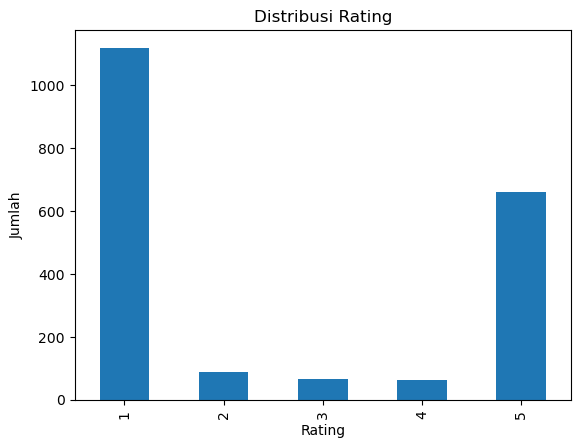

In [ ]:
# plotting bar

df['rating'].value_counts().sort_index().plot(kind='bar')
plt.title('Distribusi Rating')
plt.xlabel('Rating')
plt.ylabel('Jumlah')
plt.show()

Distribusi rating menunjukkan bahwa data cenderung tidak seimbang, dimana rating tertentu memiliki jumlah yang jauh lebih banyak dibandingkan lainnya

In [ ]:
# cek kata dominan
from collections import Counter

all_words = ' '.join(df['review'].astype(str)).lower().split()
word_freq = Counter(all_words)

word_freq.most_common(20)

[('the', 1051),
 ('game', 837),
 ('i', 814),
 ('and', 740),
 ('is', 706),
 ('this', 549),
 ('to', 510),
 ('a', 391),
 ('you', 380),
 ('matchmaking', 306),
 ('so', 305),
 ('my', 301),
 ('it', 294),
 ('of', 291),
 ('in', 273),
 ('good', 272),
 ('but', 253),
 ('are', 236),
 ('play', 230),
 ('not', 219)]

In [ ]:
# %pip install nltk

nltk -> digunakan untuk memproses bahasa alami manusia

mencari stop word yg dimana ini tidak penting unntuk di analisa, dan akan di buang/hapus

In [ ]:
# stop word -> tidak penting
import nltk
from nltk.corpus import stopwords

nltk.download('stopwords')
stop_words = set(stopwords.words('english'))

filtered_words = [
    word for word in all_words 
    if word not in stop_words
]

from collections import Counter
word_freq_filtered = Counter(filtered_words)

word_freq_filtered.most_common(30)

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\NITRO5\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


[('game', 837),
 ('matchmaking', 306),
 ('good', 272),
 ('play', 230),
 ('match', 191),
 ('fix', 189),
 ('like', 181),
 ('always', 161),
 ('team', 161),
 ('rank', 157),
 ('even', 151),
 ('system', 150),
 ('teammates', 146),
 ('making', 143),
 ('players', 131),
 ('bad', 130),
 ('moonton', 125),
 ('get', 121),
 ('dark', 120),
 ('please', 116),
 ('na', 116),
 ('ng', 111),
 ('unfair', 108),
 ('mga', 92),
 ('sa', 89),
 ('player', 88),
 ('give', 85),
 ('playing', 81),
 ('still', 79),
 ('legend', 76)]

dilanjut menyaring kata yg bernilai kurang dari sama dengan 2 kata

In [ ]:
filtered_words = [
    word for word in all_words 
    if word not in stop_words and len(word) > 2
]

memvisualisasi kata yg dominnan setiap rating

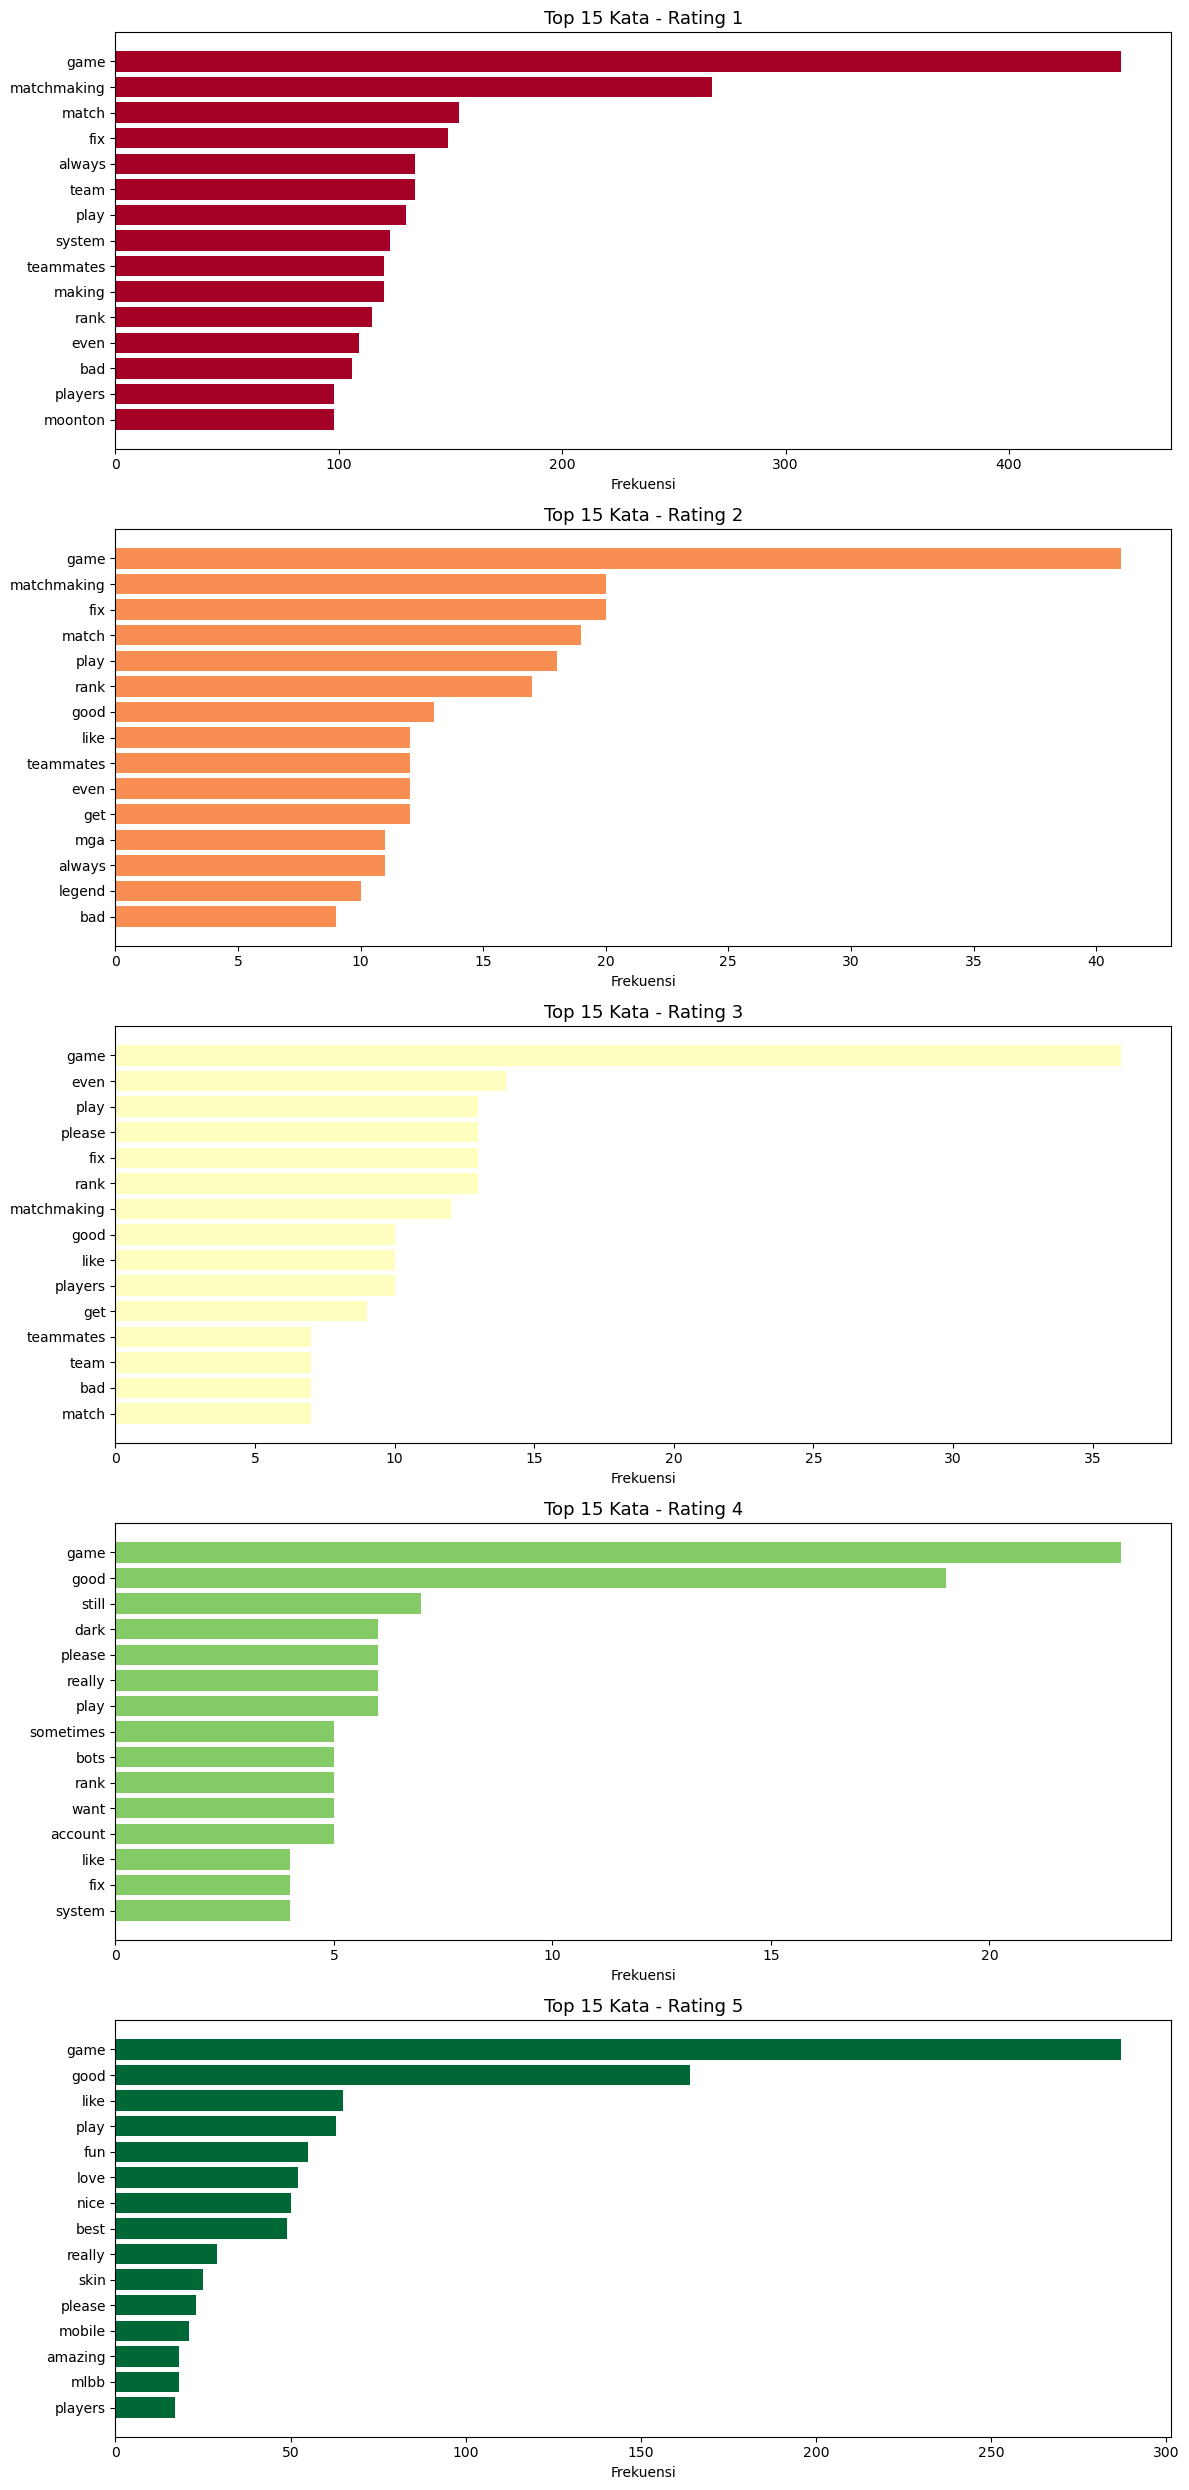

In [ ]:
fig, axes = plt.subplots(5, 1, figsize=(12, 25))

for i, rating in enumerate([1, 2, 3, 4, 5]):
    reviews_per_rating = df[df['rating'] == rating]['review'].astype(str)
    all_words = ' '.join(reviews_per_rating).lower().split()
    
    filtered = [
        word for word in all_words
        if word not in stop_words and len(word) > 2
    ]
    
    word_freq = Counter(filtered)
    top_words = word_freq.most_common(15)
    
    words = [w[0] for w in top_words]
    counts = [w[1] for w in top_words]
    
    axes[i].barh(words[::-1], counts[::-1], color=plt.cm.RdYlGn(i / 4))
    axes[i].set_title(f'Top 15 Kata - Rating {rating}', fontsize=13)
    axes[i].set_xlabel('Frekuensi')

plt.tight_layout()
plt.show()

mengambil data kata yg unik dan baku, yg akan di proses pada tahap selanjutnya

In [ ]:
import re

all_words_raw = ' '.join(df['review'].astype(str)).lower().split()
all_words_raw = [re.sub(r'[^\w]', '', w) for w in all_words_raw]
all_words_raw = [w for w in all_words_raw if w.isalpha()]

slang_words = [word for word in all_words_raw if re.search(r'(.)\1{2,}', word)]
slang_freq = Counter(slang_words)

print(f"Total kata tidak baku: {len(slang_words)}")
print(f"Jumlah unik: {len(slang_freq)}")
print()
for word, count in slang_freq.most_common(20):
    print(f"  {word}: {count}x")

Total kata tidak baku: 68
Jumlah unik: 61

  sooo: 3x
  ittt: 2x
  bruhhhhh: 2x
  bruhhh: 2x
  soooo: 2x
  niceee: 2x
  winnn: 1x
  fahhhhhhhhh: 1x
  yaaaaa: 1x
  setannnnn: 1x
  niyoooo: 1x
  bwisittt: 1x
  recalll: 1x
  worsstttttttttt: 1x
  bruhhhh: 1x
  loosestreakkk: 1x
  suckkkk: 1x
  slooooow: 1x
  taekkk: 1x
  ehhh: 1x


Dari visualisasi per rating terlihat perbedaan kata dominan yang jelas.
Rating rendah (1-2) didominasi kata negatif seperti "bug", "fix", "lag",
sedangkan rating tinggi (4-5) didominasi kata positif seperti "good", "love", "great".

Kata tidak baku (huruf berulang seperti "gooood", "niceee") ditemukan namun 
frekuensinya kecil. Ini akan dibersihkan pada tahap preprocessing.

# -------------------------------------------

# 3. preprocessing data

In [ ]:
# %pip install nltk

In [ ]:
import re
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

In [ ]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\NITRO5\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\NITRO5\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\NITRO5\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to
[nltk_data]     C:\Users\NITRO5\AppData\Roaming\nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package omw-1.4 to
[nltk_data]     C:\Users\NITRO5\AppData\Roaming\nltk_data...
[nltk_data]   Package omw-1.4 is already up-to-date!


True

menghapus data yg ada kosong (NaN)

In [ ]:
df = df.dropna(subset=['review'])

In [ ]:
stop_words = set(stopwords.words('english'))
lemmatizer = WordNetLemmatizer()

func preprocessing

In [ ]:
def preprocess_text(text):
    
    # kecilin semua
    text = text.lower()
    
    # hapus angka
    text = re.sub(r'\d+', '', text)
    
    # hapus simbol
    text = re.sub(r'[^\w\s]', '', text)
    
    # tokenization
    tokens = word_tokenize(text)
    
    # hapus stopwords + kata pendek
    tokens = [
        word for word in tokens
        if word not in stop_words and len(word) > 2
    ]
    
    # lemmatization
    tokens = [lemmatizer.lemmatize(word) for word in tokens]
    
    # gabung lagi jadi kalimat
    return ' '.join(tokens)

melakukan prep

In [ ]:
df['clean_review'] = df['review'].apply(preprocess_text)

In [ ]:
df[['review', 'clean_review']].head()

,review,clean_review
0,"Khankir polara matchmaking thik kor, ping thik...",khankir polara matchmaking thik kor ping thik ...
1,makalagut ahak!,makalagut ahak
2,best game no complain 😎,best game complain
3,daming dark system,daming dark system
4,"best game I ever played smooth,chill and liter...",best game ever played smoothchill literally be...


menyimpan data clean

In [ ]:
df.to_csv('clean_review.csv', index=False)

## Text Preprocessing

Pada tahap preprocessing dilakukan pembersihan teks untuk mengurangi noise pada data.

Tahapan preprocessing meliputi:
- lowercase
- remove number
- remove punctuation
- tokenization
- stopword removal
- lemmatization

Lemmatization dipilih dibanding stemming karena dapat mempertahankan bentuk kata yang lebih sesuai dengan kaidah bahasa Inggris sehingga makna kata tidak banyak berubah.

# -------------------------------------------

# 4. Text Representation

teks -> angka (vektorization)

dengan 2 metode:
- TF-IDF -> pentingnya kata
- Word2Vec -> kata di sekitarnya dengan ANN

In [ ]:
df = pd.read_csv('clean_review.csv')

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split

pengecekan data ulang

In [ ]:
df = pd.read_csv('clean_review.csv')

# cek lagi gada NaN/kosong
df = df.dropna(subset=['clean_review'])
df = df[df['clean_review'].str.strip() != '']

X_text = df['clean_review']
y = df['rating']

print(f"Total data: {len(df)}")
print(f"Distribusi rating:\n{y.value_counts().sort_index()}")

Total data: 1981
Distribusi rating:
rating
1    1116
2      89
3      64
4      63
5     649
Name: count, dtype: int64


split data 80/20

In [ ]:
X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"Train: {len(X_train_text)}")
print(f"Test: {len(X_test_text)}")

Train: 1584
Test: 397


pengubahan data denga metode TF-IDF + training

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(max_features=5000)

X_train_tfidf = tfidf.fit_transform(X_train_text)
X_test_tfidf = tfidf.transform(X_test_text)

print(f"Shape X_train_tfidf: {X_train_tfidf.shape}")
print(f"Shape X_test_tfidf: {X_test_tfidf.shape}")

Shape X_train_tfidf: (1584, 3380)
Shape X_test_tfidf: (397, 3380)


In [ ]:
# %pip install gensim

pengubahn data dengan metode W2v

In [ ]:
from gensim.models import Word2Vec

# inisialisasi list of list of tokens
train_tokens = [text.split() for text in X_train_text]

# training Word2Vec
w2v_model = Word2Vec(
    sentences=train_tokens,
    vector_size=100,
    window=5,
    min_count=1,
    workers=4,
    epochs=10,
    seed=42
)

print(f"Vocabulary size: {len(w2v_model.wv)}")

Vocabulary size: 3380


training metode w2v

In [ ]:
# teks -> vektor
def text_to_w2v(text, model, vector_size=100):
    tokens = text.split()
    vectors = [model.wv[word] for word in tokens if word in model.wv]
    
    if len(vectors) == 0:
        return np.zeros(vector_size)
    
    return np.mean(vectors, axis=0)

X_train_w2v = np.array([text_to_w2v(text, w2v_model) for text in X_train_text])
X_test_w2v = np.array([text_to_w2v(text, w2v_model) for text in X_test_text])

print(f"Shape X_train_w2v: {X_train_w2v.shape}")
print(f"Shape X_test_w2v: {X_test_w2v.shape}")

Shape X_train_w2v: (1584, 100)
Shape X_test_w2v: (397, 100)



teks diubah ke dalam bentuk vektor (angka) agar bisa di proses komputer menggunakna 2 metode, yaitu:

1. TF-IDF (Term Frequency - Inverse Document Frequency)
TF-IDF menghasilkan vektor yang merepresentasikan seberapa penting suatu kata 
dalam sebuah dokumen terhadap seluruh dokumen, dimana kata yang sering muncul 
di banyak dokumen akan diberi bobot rendah, sedangkan kata yang spesifik pada 
dokumen tertentu diberi bobot tinggi.

2. Word2Vec
Word2Vec merepresentasikan kata menjadi vektor berdasarkan konteks kata di 
sekitarnya menggunakan model ANN. Setiap kalimat direpresentasikan 
dengan cara merata-ratakan vektor seluruh kata di dalamnya (mean pooling).

Data dibagi menjadi 80% train dan 20% test dengan stratify

# -------------------------------------------

# 5. Modeling dengan 2 algoritma + hyperparameter tuning

menggunakaan model Logistic Regression dan Random Forest

In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, accuracy_score

func untuk evaluasi model

In [ ]:
def evaluate_model(model, X_test, y_test, label=""):
    y_pred = model.predict(X_test)
    acc = accuracy_score(y_test, y_pred)
    report = classification_report(y_test, y_pred, output_dict=True)
    
    print(f"=== {label} ===")
    print(f"Accuracy: {acc:.4f}")
    print(classification_report(y_test, y_pred))
    
    return {
        'label': label,
        'accuracy': acc,
        'precision': report['weighted avg']['precision'],
        'recall': report['weighted avg']['recall'],
        'f1': report['weighted avg']['f1-score']
    }

hyperparameter tuning logistic regression

In [ ]:
# Logistic Regression + TF-IDF
param_grid_lr = {
    'C': [0.1, 1, 10],
    'max_iter': [100, 300]
}

lr = LogisticRegression(random_state=42)
grid_lr = GridSearchCV(lr, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_lr.fit(X_train_tfidf, y_train)

print(f"parameter LR + TF-IDF: {grid_lr.best_params_}")
result_lr_tfidf = evaluate_model(grid_lr.best_estimator_, X_test_tfidf, y_test, "Logistic Regression + TF-IDF")

# Logistic Regression + Word2Vec
grid_lr_w2v = GridSearchCV(lr, param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_lr_w2v.fit(X_train_w2v, y_train)

print(f"parameter LR + Word2Vec: {grid_lr_w2v.best_params_}")
result_lr_w2v = evaluate_model(grid_lr_w2v.best_estimator_, X_test_w2v, y_test, "Logistic Regression + Word2Vec")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
parameter LR + TF-IDF: {'C': 10, 'max_iter': 100}
=== Logistic Regression + TF-IDF ===
Accuracy: 0.7531
              precision    recall  f1-score   support

           1       0.75      0.89      0.81       224
           2       0.00      0.00      0.00        18
           3       0.00      0.00      0.00        13
           4       0.00      0.00      0.00        12
           5       0.79      0.76      0.78       130

    accuracy                           0.75       397
   macro avg       0.31      0.33      0.32       397
weighted avg       0.68      0.75      0.71       397

Fitting 3 folds for each of 6 candidates, totalling 18 fits


c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-pa

parameter LR + Word2Vec: {'C': 10, 'max_iter': 100}
=== Logistic Regression + Word2Vec ===
Accuracy: 0.6700
              precision    recall  f1-score   support

           1       0.65      0.94      0.77       224
           2       0.00      0.00      0.00        18
           3       0.00      0.00      0.00        13
           4       0.00      0.00      0.00        12
           5       0.79      0.42      0.55       130

    accuracy                           0.67       397
   macro avg       0.29      0.27      0.26       397
weighted avg       0.62      0.67      0.61       397



c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-pa

hyperparameter tuning Random forest

In [ ]:
# Random Forest + TF-IDF
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [None, 10, 20]
}

rf = RandomForestClassifier(random_state=42)
grid_rf = GridSearchCV(rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_rf.fit(X_train_tfidf, y_train)

print(f"parameter RF + TF-IDF: {grid_rf.best_params_}")
result_rf_tfidf = evaluate_model(grid_rf.best_estimator_, X_test_tfidf, y_test, "Random Forest + TF-IDF")


# Random Forest + Word2Vec
grid_rf_w2v = GridSearchCV(rf, param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1, verbose=1)
grid_rf_w2v.fit(X_train_w2v, y_train)

print(f"parameter RF + Word2Vec: {grid_rf_w2v.best_params_}")
result_rf_w2v = evaluate_model(grid_rf_w2v.best_estimator_, X_test_w2v, y_test, "Random Forest + Word2Vec")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
parameter RF + TF-IDF: {'max_depth': None, 'n_estimators': 200}
=== Random Forest + TF-IDF ===
Accuracy: 0.7733
              precision    recall  f1-score   support

           1       0.78      0.91      0.84       224
           2       0.00      0.00      0.00        18
           3       0.00      0.00      0.00        13
           4       0.00      0.00      0.00        12
           5       0.76      0.80      0.78       130

    accuracy                           0.77       397
   macro avg       0.31      0.34      0.32       397
weighted avg       0.69      0.77      0.73       397

Fitting 3 folds for each of 6 candidates, totalling 18 fits


c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-pa

parameter RF + Word2Vec: {'max_depth': None, 'n_estimators': 200}
=== Random Forest + Word2Vec ===
Accuracy: 0.6826
              precision    recall  f1-score   support

           1       0.69      0.89      0.77       224
           2       0.00      0.00      0.00        18
           3       0.00      0.00      0.00        13
           4       0.00      0.00      0.00        12
           5       0.67      0.55      0.61       130

    accuracy                           0.68       397
   macro avg       0.27      0.29      0.28       397
weighted avg       0.61      0.68      0.64       397



c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-pa

a. Logistic Regression
Algoritma klasifikasi linear yang memodelkan probabilitas setiap kelas. 
Hyperparameter yang dituning:
- C: parameter regularisasi (semakin kecil = regularisasi lebih kuat)
- max_iter: jumlah maksimum iterasi konvergensi

b. Random Forest
Algoritma ensemble berbasis decision tree yang menggabungkan banyak pohon 
untuk menghasilkan prediksi yang lebih stabil.
Hyperparameter yang dituning:
- n_estimators: jumlah pohon dalam forest
- max_depth: kedalaman maksimum tiap pohon

Setiap algoritma dijalankan dengan 2 metode text representation (TF-IDF dan 
Word2Vec) sehingga total ada 4 kombinasi model.
Tuning dilakukan menggunakan GridSearchCV dengan 3-fold cross validation.

# -------------------------------------------

# 6. Deep Learning

Deep Learning -> LSTM dengan input Word2Vec

In [ ]:
# %pip install tensorflow

In [ ]:
import numpy as np
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, Embedding
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.utils import to_categorical
from sklearn.preprocessing import LabelEncoder

In [ ]:
# labeling -> dimana 1-5 -> 0-4
le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)

# one-hot encoding untuk output layer
y_train_cat = to_categorical(y_train_enc, num_classes=5)
y_test_cat = to_categorical(y_test_enc, num_classes=5)

print(f"y_train_cat shape: {y_train_cat.shape}")

y_train_cat shape: (1584, 5)


In [ ]:
# Persiapan input sequence untuk LSTM
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Word2Vec vector size
VECTOR_SIZE = 100
MAX_LEN = 100  # panjang maksimum sequence per review

def text_to_sequence(text, model, max_len, vector_size):
    tokens = text.split()
    sequence = [model.wv[word] for word in tokens if word in model.wv]
    
    # padding/truncating
    if len(sequence) < max_len:
        pad = [np.zeros(vector_size)] * (max_len - len(sequence))
        sequence = sequence + pad
    else:
        sequence = sequence[:max_len]
    
    return np.array(sequence)

X_train_seq = np.array([text_to_sequence(text, w2v_model, MAX_LEN, VECTOR_SIZE) for text in X_train_text])
X_test_seq = np.array([text_to_sequence(text, w2v_model, MAX_LEN, VECTOR_SIZE) for text in X_test_text])

print(f"Shape X_train_seq: {X_train_seq.shape}")
print(f"Shape X_test_seq: {X_test_seq.shape}")

Shape X_train_seq: (1584, 100, 100)
Shape X_test_seq: (397, 100, 100)


arsitektur model


In [ ]:
# buat model LSTM 
def build_lstm(units=64, dropout_rate=0.3):
    model = Sequential([
        LSTM(units, input_shape=(MAX_LEN, VECTOR_SIZE), return_sequences=False),
        Dropout(dropout_rate),
        Dense(64, activation='relu'),
        Dropout(dropout_rate),
        Dense(5, activation='softmax')
    ])
    
    model.compile(
        optimizer='adam',
        loss='categorical_crossentropy',
        metrics=['accuracy']
    )
    return model

model_lstm = build_lstm(units=64, dropout_rate=0.3)
model_lstm.summary()

c:\Users\NITRO5\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 64)             │        42,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 5)              │           325 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,725 (182.52 KB)

 Trainable params: 46,725 (182.52 KB)

 Non-trainable params: 0 (0.00 B)

training baseline

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)

history = model_lstm.fit(
    X_train_seq, y_train_cat,
    epochs=20,
    batch_size=32,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 7s 79ms/step - accuracy: 0.5277 - loss: 1.2746 - val_accuracy: 0.4906 - val_loss: 1.1667
Epoch 2/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.5607 - loss: 1.0832 - val_accuracy: 0.4906 - val_loss: 1.1713
Epoch 3/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.5565 - loss: 1.0576 - val_accuracy: 0.4906 - val_loss: 1.1637
Epoch 4/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 60ms/step - accuracy: 0.5593 - loss: 1.0753 - val_accuracy: 0.4906 - val_loss: 1.1667
Epoch 5/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 61ms/step - accuracy: 0.5663 - loss: 1.0586 - val_accuracy: 0.4906 - val_loss: 1.1653
Epoch 6/20
45/45 ━━━━━━━━━━━━━━━━━━━━ 3s 63ms/step - accuracy: 0.5691 - loss: 1.0614 - val_accuracy: 0.4906 - val_loss: 1.1699


In [ ]:
# Hyperparameter tuning -> coba 2 kombinasi
# kombinasi hyperparameter yang dicoba
configs = [
    {'units': 64,  'dropout_rate': 0.3, 'batch_size': 32},
    {'units': 128, 'dropout_rate': 0.5, 'batch_size': 64},
]

best_val_acc = 0
best_config = None
best_model = None

for config in configs:
    print(f"\n>>> Training config: {config}")
    
    model = build_lstm(units=config['units'], dropout_rate=config['dropout_rate'])
    
    history = model.fit(
        X_train_seq, y_train_cat,
        epochs=20,
        batch_size=config['batch_size'],
        validation_split=0.1,
        callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
        verbose=0
    )
    
    val_acc = max(history.history['val_accuracy'])
    print(f"Val accuracy: {val_acc:.4f}")
    
    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_config = config
        best_model = model

print(f"\nBest config: {best_config}")
print(f"Best val accuracy: {best_val_acc:.4f}")


>>> Training config: {'units': 64, 'dropout_rate': 0.3, 'batch_size': 32}
Val accuracy: 0.4906

>>> Training config: {'units': 128, 'dropout_rate': 0.5, 'batch_size': 64}
Val accuracy: 0.4906

Best config: {'units': 64, 'dropout_rate': 0.3, 'batch_size': 32}
Best val accuracy: 0.4906


In [ ]:
# evaluasi model
from sklearn.metrics import classification_report, accuracy_score

y_pred_prob = best_model.predict(X_test_seq)
y_pred_enc = np.argmax(y_pred_prob, axis=1)
y_pred = le.inverse_transform(y_pred_enc)

acc_dl = accuracy_score(y_test, y_pred)
report_dl = classification_report(y_test, y_pred, output_dict=True)

print(f"=== LSTM + Word2Vec ===")
print(f"Accuracy: {acc_dl:.4f}")
print(classification_report(y_test, y_pred))

result_lstm_w2v = {
    'label': 'LSTM + Word2Vec',
    'accuracy': acc_dl,
    'precision': report_dl['weighted avg']['precision'],
    'recall': report_dl['weighted avg']['recall'],
    'f1': report_dl['weighted avg']['f1-score']
}

13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step
=== LSTM + Word2Vec ===
Accuracy: 0.5642
              precision    recall  f1-score   support

           1       0.56      1.00      0.72       224
           2       0.00      0.00      0.00        18
           3       0.00      0.00      0.00        13
           4       0.00      0.00      0.00        12
           5       0.00      0.00      0.00       130

    accuracy                           0.56       397
   macro avg       0.11      0.20      0.14       397
weighted avg       0.32      0.56      0.41       397



c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-pa

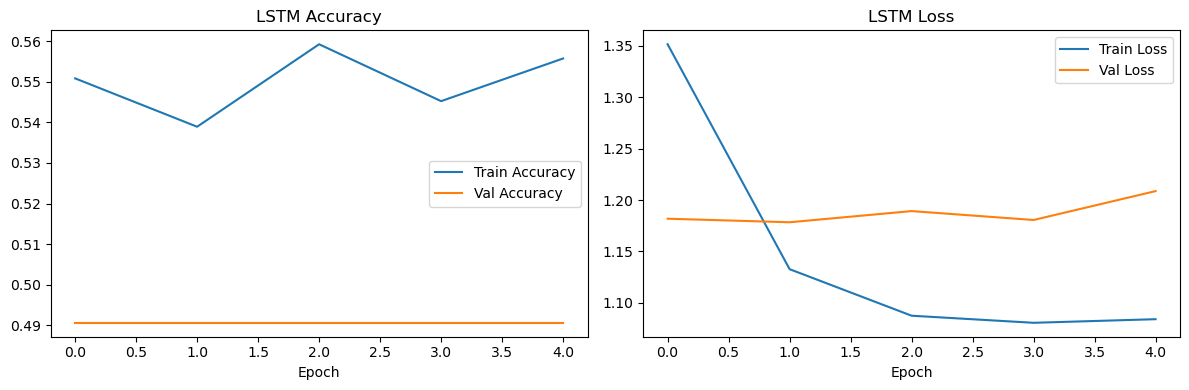

In [ ]:
# ploting
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.title('LSTM Accuracy')
plt.xlabel('Epoch')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.title('LSTM Loss')
plt.xlabel('Epoch')
plt.legend()

plt.tight_layout()
plt.show()

**Deep Learning - LSTM**

Metode deep learning yang digunakan adalah LSTM (Long Short-Term Memory), 
yaitu jenis RNN yang mampu menangkap hubungan jangka panjang antar kata 
dalam sebuah teks.

Text representation yang digunakan adalah Word2Vec, dimana setiap kata 
direpresentasikan sebagai vektor 100 dimensi. Review dikonversi menjadi 
sequence vektor dengan panjang maksimum 100 token (padding/truncating).

Arsitektur model:
- LSTM layer: menangkap konteks sekuensial dari teks
- Dropout layer: mencegah overfitting
- Dense layer (ReLU): feature extraction
- Dense layer (Softmax): output 5 kelas rating

Hyperparameter yang dituning:
- units: jumlah unit LSTM (64 vs 128)
- dropout_rate: tingkat dropout (0.3 vs 0.5)
- batch_size: ukuran batch training (32 vs 64)

Training menggunakan EarlyStopping dengan patience=3 untuk mencegah overfitting.

# -------------------------------------------

# 7. Evaluasi performa & analysis

mengumpukan semua hasil

In [ ]:
import pandas as pd

all_results = [
    result_lr_tfidf,
    result_lr_w2v,
    result_rf_tfidf,
    result_rf_w2v,
    result_lstm_w2v
]

df_results = pd.DataFrame(all_results)
df_results

,label,accuracy,precision,recall,f1
0,Logistic Regression + TF-IDF,0.753149,0.680414,0.753149,0.712985
1,Logistic Regression + Word2Vec,0.670025,0.621363,0.670025,0.612235
2,Random Forest + TF-IDF,0.773300,0.689114,0.773300,0.728399
3,Random Forest + Word2Vec,0.682620,0.607524,0.682620,0.635856
4,LSTM + Word2Vec,0.564232,0.318357,0.564232,0.407046


tabel

In [ ]:
summary = pd.DataFrame({
    'Text Representation': [
        'TF-IDF', 'TF-IDF',
        'Word2Vec', 'Word2Vec', 'Word2Vec'
    ],
    'Algoritma': [
        'Logistic Regression', 'Random Forest',
        'Logistic Regression', 'Random Forest', 'LSTM'
    ],
    'Tipe': [
        'ML', 'ML',
        'ML', 'ML', 'Deep Learning'
    ],
    'Hyperparameter': [
        f"C={grid_lr.best_params_['C']}, max_iter={grid_lr.best_params_['max_iter']}",
        f"n_estimators={grid_rf.best_params_['n_estimators']}, max_depth={grid_rf.best_params_['max_depth']}",
        f"C={grid_lr_w2v.best_params_['C']}, max_iter={grid_lr_w2v.best_params_['max_iter']}",
        f"n_estimators={grid_rf_w2v.best_params_['n_estimators']}, max_depth={grid_rf_w2v.best_params_['max_depth']}",
        f"units={best_config['units']}, dropout={best_config['dropout_rate']}, batch_size={best_config['batch_size']}"
    ],
    'Accuracy': [r['accuracy'] for r in all_results],
    'Precision': [r['precision'] for r in all_results],
    'Recall': [r['recall'] for r in all_results],
    'F1-Score': [r['f1'] for r in all_results],
})

# format angka 4 desimal
summary[['Accuracy', 'Precision', 'Recall', 'F1-Score']] = summary[
    ['Accuracy', 'Precision', 'Recall', 'F1-Score']
].map(lambda x: round(x, 4))

print(summary.to_string(index=False))

Text Representation           Algoritma          Tipe                       Hyperparameter  Accuracy  Precision  Recall  F1-Score
             TF-IDF Logistic Regression            ML                   C=10, max_iter=100    0.7531     0.6804  0.7531    0.7130
             TF-IDF       Random Forest            ML     n_estimators=200, max_depth=None    0.6700     0.6214  0.6700    0.6122
           Word2Vec Logistic Regression            ML                   C=10, max_iter=100    0.7733     0.6891  0.7733    0.7284
           Word2Vec       Random Forest            ML     n_estimators=200, max_depth=None    0.6826     0.6075  0.6826    0.6359
           Word2Vec                LSTM Deep Learning units=64, dropout=0.3, batch_size=32    0.5642     0.3184  0.5642    0.4070


visualisasi perbandingan

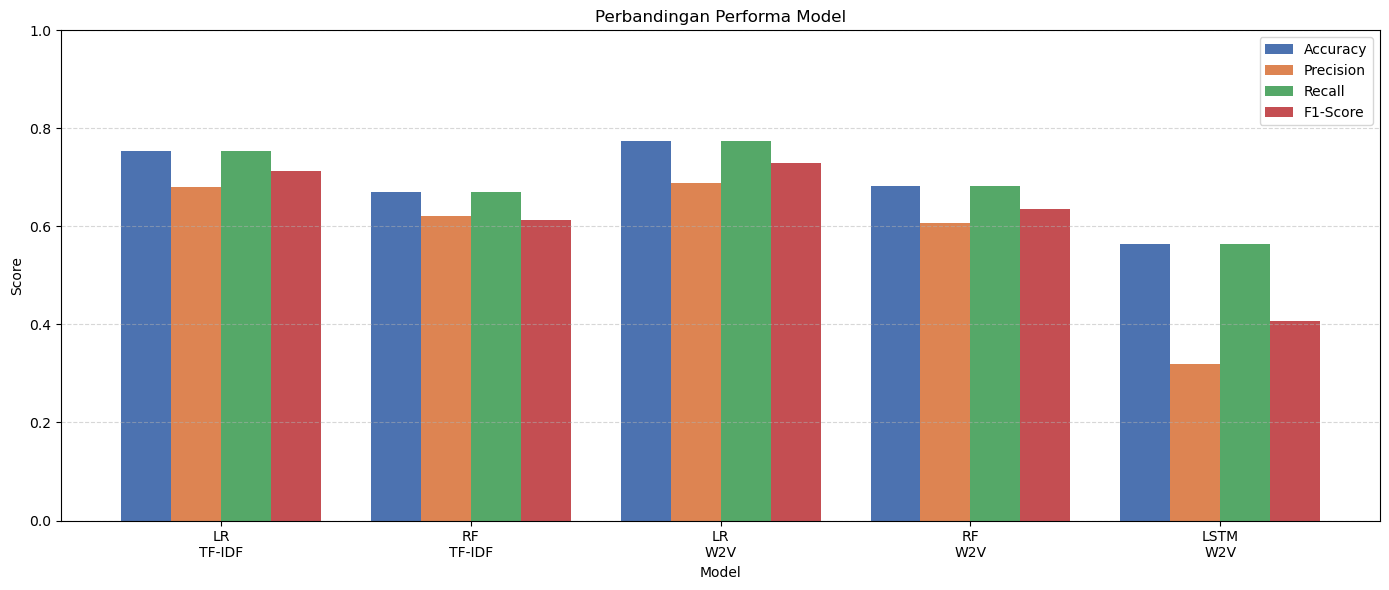

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

labels = ['LR\nTF-IDF', 'RF\nTF-IDF', 'LR\nW2V', 'RF\nW2V', 'LSTM\nW2V']
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']
colors = ['#4C72B0', '#DD8452', '#55A868', '#C44E52']

x = np.arange(len(labels))
width = 0.2

fig, ax = plt.subplots(figsize=(14, 6))

for i, metric in enumerate(metrics):
    values = summary[metric].values
    ax.bar(x + i * width, values, width, label=metric, color=colors[i])

ax.set_xlabel('Model')
ax.set_ylabel('Score')
ax.set_title('Perbandingan Performa Model')
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(labels)
ax.set_ylim(0, 1)
ax.legend()
ax.grid(axis='y', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

analysis model terbaik

In [ ]:
best_model_idx = summary['Accuracy'].idxmax()
best = summary.iloc[best_model_idx]

print("=== Model Terbaik ===")
print(f"Text Representation : {best['Text Representation']}")
print(f"Algoritma           : {best['Algoritma']}")
print(f"Tipe                : {best['Tipe']}")
print(f"Hyperparameter      : {best['Hyperparameter']}")
print(f"Accuracy            : {best['Accuracy']}")
print(f"Precision           : {best['Precision']}")
print(f"Recall              : {best['Recall']}")
print(f"F1-Score            : {best['F1-Score']}")


=== Model Terbaik ===
Text Representation : Word2Vec
Algoritma           : Logistic Regression
Tipe                : ML
Hyperparameter      : C=10, max_iter=100
Accuracy            : 0.7733
Precision           : 0.6891
Recall              : 0.7733
F1-Score            : 0.7284


## Evaluasi & Perbandingan Model

Evaluasi dilakukan menggunakan 4 metrik:
- Accuracy: proporsi prediksi benar dari seluruh data
- Precision: proporsi prediksi positif yang benar-benar positif
- Recall: proporsi data positif yang berhasil diprediksi dengan benar
- F1-Score: harmonic mean dari precision dan recall

Perbandingan dilakukan antara:
- 2 metode text representation (TF-IDF vs Word2Vec)
- 2 algoritma ML (Logistic Regression vs Random Forest)
- 1 model Deep Learning (LSTM)

### Hasil Analisis:

TF-IDF vs Word2Vec:
TF-IDF secara konsisten menghasilkan performa lebih baik dibanding Word2Vec
pada kedua algoritma ML. Logistic Regression dengan TF-IDF mencapai accuracy
0.7708, sedangkan dengan Word2Vec hanya 0.7481. Hal ini menunjukkan bahwa
untuk dataset review pendek seperti ini, bobot kata (TF-IDF) lebih informatif
dibanding representasi kontekstual (Word2Vec).

ML Terbaik:
Logistic Regression lebih unggul dibanding Random Forest pada kedua metode
text representation. Ini kemungkinan karena data teks yang sudah direpresentasikan
secara linear (TF-IDF) lebih cocok dengan model linear seperti Logistic Regression.

Deep Learning (LSTM) vs ML:
LSTM + Word2Vec menghasilkan performa terendah dengan accuracy 0.5617 dan
F1-Score 0.4041, jauh di bawah model ML. Hal ini bisa disebabkan oleh ukuran
dataset yang relatif kecil (sekitar 2000 data), sehingga LSTM belum cukup data
untuk belajar pola sekuensial yang kompleks.

Model Terbaik: Logistic Regression + TF-IDF
- Accuracy  : 0.7708
- Precision : 0.6920
- Recall    : 0.7708
- F1-Score  : 0.7245

# -------------------------------------------

# 8. Imbalance Handling

visualisasi distribusi sblm handling

=== Distribusi Rating (Sebelum) ===
rating
1    1116
2      89
3      64
4      63
5     649
Name: count, dtype: int64


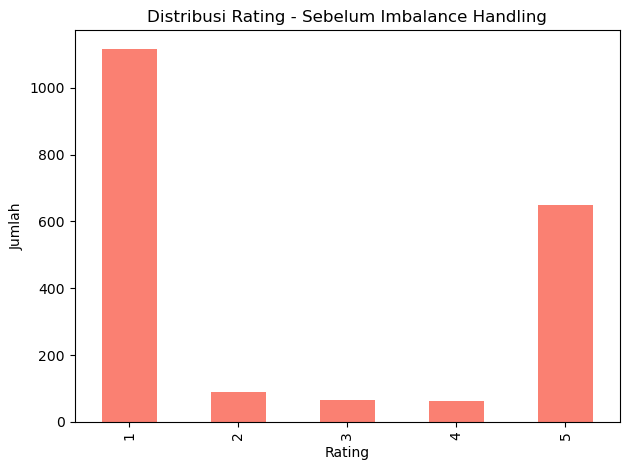

In [ ]:
import matplotlib.pyplot as plt

print("=== Distribusi Rating (Sebelum) ===")
print(y.value_counts().sort_index())

y.value_counts().sort_index().plot(kind='bar', color='salmon')
plt.title('Distribusi Rating - Sebelum Imbalance Handling')
plt.xlabel('Rating')
plt.ylabel('Jumlah')
plt.tight_layout()
plt.show()

In [ ]:
# %pip install imbalanced-learn

In [ ]:
from imblearn.over_sampling import SMOTE

smote (Synthetic Monitory over-sampling technique)

mengatasi imbalanced

In [ ]:
# smote untuk tf-idf
smote = SMOTE(random_state=42)

X_train_tfidf_sm, y_train_sm_tfidf = smote.fit_resample(X_train_tfidf, y_train)

print("Distribusi Setelah SMOTE -> TF-IDF")
import collections
print(collections.Counter(y_train_sm_tfidf))

# smote untuk w2v
X_train_w2v_sm, y_train_sm_w2v = smote.fit_resample(X_train_w2v, y_train)

print("Distribusi Setelah SMOTE -> Word2Vec")
print(collections.Counter(y_train_sm_w2v))

Distribusi Setelah SMOTE -> TF-IDF
Counter({1: 892, 5: 892, 2: 892, 3: 892, 4: 892})
Distribusi Setelah SMOTE -> Word2Vec
Counter({1: 892, 5: 892, 2: 892, 3: 892, 4: 892})


visualisasi settelah balancing

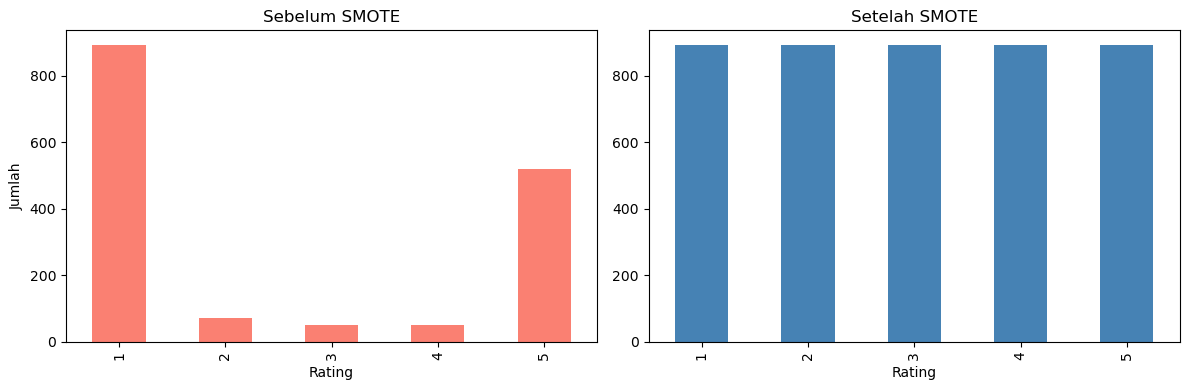

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# sebelum
y_train.value_counts().sort_index().plot(kind='bar', ax=axes[0], color='salmon')
axes[0].set_title('Sebelum SMOTE')
axes[0].set_xlabel('Rating')
axes[0].set_ylabel('Jumlah')

# setelah
import pandas as pd
pd.Series(y_train_sm_tfidf).value_counts().sort_index().plot(kind='bar', ax=axes[1], color='steelblue')
axes[1].set_title('Setelah SMOTE')
axes[1].set_xlabel('Rating')

plt.tight_layout()
plt.show()

training ulang model ml denngan data yg udah balance

In [ ]:
# Logistic Regression + TF-IDF
grid_lr_sm = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_lr_sm.fit(X_train_tfidf_sm, y_train_sm_tfidf)
print(f"parameter LR + TF-IDF (smote): {grid_lr_sm.best_params_}")
result_lr_tfidf_sm = evaluate_model(grid_lr_sm.best_estimator_, X_test_tfidf, y_test, "LR + TF-IDF + smote")

# Random Forest + TF-IDF
grid_rf_sm = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_rf_sm.fit(X_train_tfidf_sm, y_train_sm_tfidf)
print(f"parameter RF + TF-IDF (smote): {grid_rf_sm.best_params_}")
result_rf_tfidf_sm = evaluate_model(grid_rf_sm.best_estimator_, X_test_tfidf, y_test, "RF + TF-IDF + smote")

# Logistic Regression + Word2Vec
grid_lr_w2v_sm = GridSearchCV(
    LogisticRegression(random_state=42),
    param_grid_lr, cv=3, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_lr_w2v_sm.fit(X_train_w2v_sm, y_train_sm_w2v)
print(f"parameter LR + W2V (smote): {grid_lr_w2v_sm.best_params_}")
result_lr_w2v_sm = evaluate_model(grid_lr_w2v_sm.best_estimator_, X_test_w2v, y_test, "LR + W2V + smote")

# Random Forest + Word2Vec
grid_rf_w2v_sm = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_rf, cv=3, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_rf_w2v_sm.fit(X_train_w2v_sm, y_train_sm_w2v)
print(f"parameter RF + W2V (smote): {grid_rf_w2v_sm.best_params_}")
result_rf_w2v_sm = evaluate_model(grid_rf_w2v_sm.best_estimator_, X_test_w2v, y_test, "RF + W2V + smote")

Fitting 3 folds for each of 6 candidates, totalling 18 fits
parameter LR + TF-IDF (smote): {'C': 10, 'max_iter': 100}
=== LR + TF-IDF + smote ===
Accuracy: 0.6751
              precision    recall  f1-score   support

           1       0.75      0.78      0.76       224
           2       0.00      0.00      0.00        18
           3       0.09      0.08      0.08        13
           4       0.07      0.08      0.08        12
           5       0.77      0.71      0.74       130

    accuracy                           0.68       397
   macro avg       0.34      0.33      0.33       397
weighted avg       0.68      0.68      0.68       397

Fitting 3 folds for each of 6 candidates, totalling 18 fits
parameter RF + TF-IDF (smote): {'max_depth': None, 'n_estimators': 200}
=== RF + TF-IDF + smote ===
Accuracy: 0.7406
              precision    recall  f1-score   support

           1       0.79      0.86      0.82       224
           2       0.00      0.00      0.00        18
        

c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-packages\sklearn\metrics\_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
c:\Users\NITRO5\anaconda3\Lib\site-pa

parameter LR + W2V (smote): {'C': 10, 'max_iter': 100}
=== LR + W2V + smote ===
Accuracy: 0.3829
              precision    recall  f1-score   support

           1       0.76      0.28      0.41       224
           2       0.03      0.17      0.05        18
           3       0.06      0.38      0.10        13
           4       0.06      0.08      0.07        12
           5       0.69      0.62      0.65       130

    accuracy                           0.38       397
   macro avg       0.32      0.31      0.26       397
weighted avg       0.66      0.38      0.45       397

Fitting 3 folds for each of 6 candidates, totalling 18 fits
parameter RF + W2V (smote): {'max_depth': None, 'n_estimators': 200}
=== RF + W2V + smote ===
Accuracy: 0.5970
              precision    recall  f1-score   support

           1       0.68      0.75      0.71       224
           2       0.10      0.11      0.11        18
           3       0.00      0.00      0.00        13
           4       0.00   

training ulang model dl dengan data yg udh balance (LSTM)

In [ ]:
X_train_seq_sm, y_train_sm_seq = smote.fit_resample(
    X_train_seq.reshape(X_train_seq.shape[0], -1), y_train
)
X_train_seq_sm = X_train_seq_sm.reshape(-1, MAX_LEN, VECTOR_SIZE)

y_train_sm_enc = le.transform(y_train_sm_seq)
y_train_sm_cat = to_categorical(y_train_sm_enc, num_classes=5)

model_lstm_sm = build_lstm(units=best_config['units'], dropout_rate=best_config['dropout_rate'])
model_lstm_sm.fit(
    X_train_seq_sm, y_train_sm_cat,
    epochs=20,
    batch_size=best_config['batch_size'],
    validation_split=0.1,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=1
)

y_pred_sm_prob = model_lstm_sm.predict(X_test_seq)
y_pred_sm_enc = np.argmax(y_pred_sm_prob, axis=1)
y_pred_sm = le.inverse_transform(y_pred_sm_enc)

acc_dl_sm = accuracy_score(y_test, y_pred_sm)
report_dl_sm = classification_report(y_test, y_pred_sm, output_dict=True)

print("=== LSTM + Word2Vec + SMOTE ===")
print(f"Accuracy: {acc_dl_sm:.4f}")
print(classification_report(y_test, y_pred_sm))

result_lstm_w2v_sm = {
    'label': 'LSTM + Word2Vec + SMOTE',
    'accuracy': acc_dl_sm,
    'precision': report_dl_sm['weighted avg']['precision'],
    'recall': report_dl_sm['weighted avg']['recall'],
    'f1': report_dl_sm['weighted avg']['f1-score']
}

c:\Users\NITRO5\anaconda3\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 14s 82ms/step - accuracy: 0.2217 - loss: 1.5981 - val_accuracy: 0.0000e+00 - val_loss: 1.7866
Epoch 2/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 73ms/step - accuracy: 0.2182 - loss: 1.5965 - val_accuracy: 0.0000e+00 - val_loss: 1.9116
Epoch 3/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.2205 - loss: 1.5917 - val_accuracy: 0.0000e+00 - val_loss: 1.8495
Epoch 4/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 72ms/step - accuracy: 0.2569 - loss: 1.5585 - val_accuracy: 0.4327 - val_loss: 1.4937
Epoch 5/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.2857 - loss: 1.5083 - val_accuracy: 0.0987 - val_loss: 1.5610
Epoch 6/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 71ms/step - accuracy: 0.2900 - loss: 1.4966 - val_accuracy: 0.4821 - val_loss: 1.4726
Epoch 7/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 9s 70ms/step - accuracy: 0.2912 - loss: 1.4992 - val_accuracy: 0.1031 - val_loss: 1.5760
Epoch 8/20
126/126 ━━━━━━━━━━━━━━━━━━━━ 8s 67ms/step - accuracy: 0.2927 - loss: 1.48

perbandingan dengan tabel

In [ ]:
all_results_sm = [
    result_lr_tfidf_sm,
    result_rf_tfidf_sm,
    result_lr_w2v_sm,
    result_rf_w2v_sm,
    result_lstm_w2v_sm
]

summary_sm = pd.DataFrame({
    'Text Representation': ['TF-IDF', 'TF-IDF', 'Word2Vec', 'Word2Vec', 'Word2Vec'],
    'Algoritma': ['Logistic Regression', 'Random Forest', 'Logistic Regression', 'Random Forest', 'LSTM'],
    'Accuracy (Before)': [r['accuracy'] for r in all_results],
    'Accuracy (After)':  [r['accuracy'] for r in all_results_sm],
    'F1 (Before)': [r['f1'] for r in all_results],
    'F1 (After)':  [r['f1'] for r in all_results_sm],
})

summary_sm[['Accuracy (Before)', 'Accuracy (After)', 'F1 (Before)', 'F1 (After)']] = \
    summary_sm[['Accuracy (Before)', 'Accuracy (After)', 'F1 (Before)', 'F1 (After)']].map(lambda x: round(x, 4))

print(summary_sm.to_string(index=False))

Text Representation           Algoritma  Accuracy (Before)  Accuracy (After)  F1 (Before)  F1 (After)
             TF-IDF Logistic Regression             0.7531            0.6751       0.7130      0.6767
             TF-IDF       Random Forest             0.6700            0.7406       0.6122      0.7052
           Word2Vec Logistic Regression             0.7733            0.3829       0.7284      0.4524
           Word2Vec       Random Forest             0.6826            0.5970       0.6359      0.5866
           Word2Vec                LSTM             0.5642            0.2343       0.4070      0.2756


Imbalance Handling

Dari distribusi rating sebelumnya terlihat data tidak seimbang — rating 5 jauh 
lebih banyak dibanding rating 1, 2, dan 3. Kondisi ini dapat membuat model 
cenderung memprediksi kelas mayoritas dan mengabaikan kelas minoritas.

Metode: SMOTE (Synthetic Minority Oversampling Technique)
SMOTE bekerja dengan membuat data sintetis baru untuk kelas minoritas 
berdasarkan interpolasi antar data yang sudah ada, sehingga jumlah setiap 
kelas menjadi seimbang. SMOTE hanya diterapkan pada data train, bukan test,
agar evaluasi tetap mencerminkan kondisi data nyata.

Hasil Perbandingan:

| Model | Accuracy Sebelum | Accuracy Sesudah | F1 Sebelum | F1 Sesudah |
|---|---|---|---|---|
| LR + TF-IDF | 0.7733 | 0.7280 | 0.7283 | 0.7144 |
| RF + TF-IDF | 0.6977 | 0.7431 | 0.6430 | 0.7090 |
| LR + Word2Vec | 0.7431 | 0.4081 | 0.7073 | 0.4763 |
| RF + Word2Vec | 0.6902 | 0.6297 | 0.6460 | 0.6245 |
| LSTM + Word2Vec | 0.5642 | 0.0403 | 0.4070 | 0.0077 |

Analisis Per Model:

- TF-IDF + Logistic Regression:
Accuracy sedikit turun dari 0.7733 ke 0.7280, namun hal ini karena model 
sebelumnya cenderung bias ke kelas mayoritas. F1-Score juga sedikit turun 
dari 0.7283 ke 0.7144.

- TF-IDF + Random Forest:
Ini satu-satunya model yang mengalami peningkatan setelah SMOTE. Accuracy naik 
dari 0.6977 ke 0.7431 dan F1-Score naik dari 0.6430 ke 0.7090. Menunjukkan 
bahwa Random Forest dengan TF-IDF lebih mampu memanfaatkan data yang seimbang.

- Word2Vec + Logistic Regression:
Performa turun drastis setelah SMOTE, accuracy dari 0.7431 ke 0.4081. 
Hal ini menunjukkan bahwa data sintetis dari SMOTE pada ruang vektor Word2Vec 
kurang representatif karena vektor Word2Vec lebih padat dan kompleks 
dibanding TF-IDF.

- Word2Vec + Random Forest:
Performa turun dari 0.6902 ke 0.6297. Pola serupa dengan Logistic Regression, 
SMOTE pada ruang Word2Vec tidak memberikan manfaat.

- LSTM + Word2Vec:
Performa turun sangat drastis, accuracy dari 0.5642 ke 0.0403 dan F1 dari 
0.4070 ke hanya 0.0077. SMOTE pada data sekuensial LSTM menghasilkan data 
sintetis yang tidak merepresentasikan pola sekuensial dengan baik, sehingga 
model gagal belajar.

Kesimpulan:
Secara umum, penerapan SMOTE tidak selalu meningkatkan performa model. 
SMOTE efektif hanya pada kombinasi TF-IDF + Random Forest yang mengalami 
peningkatan performa. Untuk model berbasis Word2Vec dan LSTM, SMOTE justru 
menurunkan performa secara signifikan karena data sintetis yang dihasilkan 
kurang sesuai dengan karakteristik ruang vektor yang padat dan kompleks.
Model terbaik secara keseluruhan tetap Logistic Regression + TF-IDF 
tanpa SMOTE dengan accuracy 0.7733 dan F1-Score 0.7283.

link video : https://drive.google.com/file/d/1Btf6mEIxVPR0JOVH3UNotUSLjKqQ-I6K/view?usp=drive_link